# AlphaEvolve + **SmolVLM2-2.2B-Instruct** on **PlotQA** — Google Colab

Runs **AlphaEvolve** (`evolve_plotqa.py`) on **jrc/cleaned-plotqa-v2 train** with backbone **`HuggingFaceTB/SmolVLM2-2.2B-Instruct`** (override via `VLM_HF_ID`).

**GPU:** T4-friendly small-footprint VLM from Hugging Face.

**Colab:** **Runtime → GPU**. **Secrets:** `HF_TOKEN`, `GEMINI_API_KEY`.

**Project path:** `/content/evolving-vlm-325/evolving-vlm-inference-main` (upload or `GIT_REPO_URL`).


In [ ]:
import os
from pathlib import Path

PROJECT_ROOT = Path(os.environ.get("COLAB_PROJECT_ROOT", "/content/evolving-vlm-325/evolving-vlm-inference-main"))
GIT_REPO_URL = os.environ.get("GIT_REPO_URL", "")

VLM_SLUG = "smolvlm2"
VLM_HF_ID = os.environ.get("VLM_HF_ID", "HuggingFaceTB/SmolVLM2-2.2B-Instruct")
os.environ["VLM_HF_ID"] = VLM_HF_ID

NUM_GENERATIONS = int(os.environ.get("NUM_GENERATIONS", "3"))
POPULATION_SIZE = int(os.environ.get("POPULATION_SIZE", "6"))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("VLM:", VLM_HF_ID, f"({VLM_SLUG})")
print("NUM_GENERATIONS:", NUM_GENERATIONS, "POPULATION_SIZE:", POPULATION_SIZE)
print("GPU note:", 'T4-friendly small-footprint VLM from Hugging Face.')



PROJECT_ROOT: /content/evolving-vlm-325/evolving-vlm-inference-main
VLM: HuggingFaceTB/SmolVLM2-2.2B-Instruct (smolvlm2)
NUM_GENERATIONS: 3 POPULATION_SIZE: 6
GPU note: T4-friendly small-footprint VLM from Hugging Face.


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/projectFiles.zip")  # change if your file name differs
out_dir = Path("/content")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(out_dir)

# If the zip already contains a top-level folder "evolving-vlm-inference-main", you're done.
# If it extracted into a wrong name, rename so this path exists:
assert (out_dir / "evolving-vlm-325/evolving-vlm-inference-main").is_dir(), list(out_dir.iterdir())



In [ ]:
%%capture
!pip install -q "transformers>=4.48.0" num2words torch torchvision pillow accelerate google-generativeai bitsandbytes datasets huggingface_hub



In [ ]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU. In Colab: Runtime → Change runtime type → GPU (e.g. T4), then re-run."
    )
print("GPU:", torch.cuda.get_device_name(0))



GPU: NVIDIA A100-SXM4-40GB


In [ ]:
import os, shutil, subprocess
from pathlib import Path

if GIT_REPO_URL:
    if PROJECT_ROOT.exists():
        shutil.rmtree(PROJECT_ROOT)
    subprocess.run(["git", "clone", "--depth", "1", GIT_REPO_URL, str(PROJECT_ROOT)], check=True)
elif not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"{PROJECT_ROOT} not found. Upload repo to /content/evolving-vlm-325/evolving-vlm-inference-main or set GIT_REPO_URL."
    )

os.chdir(PROJECT_ROOT)
print("cwd:", os.getcwd())



cwd: /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
import os
import re
import shutil
from pathlib import Path

os.environ["VLM_HF_ID"] = VLM_HF_ID
_src = PROJECT_ROOT / "seeds" / "seed_smolvlm2.py"
_dst = PROJECT_ROOT / "seed_instruct.py"
if not _src.is_file():
    raise FileNotFoundError(f"Missing seed: {_src} — upload the full repo or re-run tools/restore_colab_notebooks.py")
text = _src.read_text(encoding="utf-8")
text = re.sub(r'_DEFAULT_MODEL = "[^"]+"', f'_DEFAULT_MODEL = "{VLM_HF_ID}"', text, count=1)
_dst.write_text(text, encoding="utf-8")
print("Deployed", _dst, "for", VLM_HF_ID)



Deployed /content/evolving-vlm-325/evolving-vlm-inference-main/seed_instruct.py for HuggingFaceTB/SmolVLM2-2.2B-Instruct


In [ ]:
# Optional: upload evolve_plotqa.py / evolved_plotqa.py into PROJECT_ROOT (Colab sidebar).
print("Optional: upload evolve_plotqa.py or evolved_plotqa.py into", PROJECT_ROOT)



Optional: upload evolve_plotqa.py or evolved_plotqa.py into /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
import os
from google.colab import userdata

try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    from huggingface_hub import login
    login()

try:
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
except Exception:
    pass

if not os.environ.get("GEMINI_API_KEY"):
    from getpass import getpass
    os.environ["GEMINI_API_KEY"] = getpass("Enter GEMINI_API_KEY: ")

assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is required."



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Enter GEMINI_API_KEY: ··········


In [ ]:
import os
import sys
import importlib.util
from pathlib import Path

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))


def load_module(name: str, path: Path):
    spec = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(m)
    return m


from datasets import load_dataset

_sample_dir = Path("/tmp/plotqa_colab_sample")
_sample_dir.mkdir(parents=True, exist_ok=True)
_ds = load_dataset("jrc/cleaned-plotqa-v2", split="train")
_row = _ds[0]
_img = _row["image"]
_p = _sample_dir / "sample0.png"
if hasattr(_img, "convert"):
    _img.convert("RGB").save(_p)
_q = (_row.get("user") or "").strip().split("\n", 1)[0].strip()
_gold = str(_row.get("assistant") or "").strip()
SAMPLE = {"image_path": str(_p), "question": _q, "qid": None, "gold": _gold}
print("Sample:", SAMPLE["question"][:120], "Gold:", SAMPLE["gold"])



README.md:   0%|          | 0.00/363 [00:00<?, ?B/s]

data/train-00000-of-00015.parquet:   0%|          | 0.00/8.14M [00:00<?, ?B/s]

data/train-00001-of-00015.parquet:   0%|          | 0.00/7.85M [00:00<?, ?B/s]

data/train-00002-of-00015.parquet:   0%|          | 0.00/8.19M [00:00<?, ?B/s]

data/train-00003-of-00015.parquet:   0%|          | 0.00/8.05M [00:00<?, ?B/s]

...

data/train-00012-of-00015.parquet:   0%|          | 0.00/7.63M [00:00<?, ?B/s]

data/train-00013-of-00015.parquet:   0%|          | 0.00/8.62M [00:00<?, ?B/s]

data/train-00014-of-00015.parquet:   0%|          | 0.00/8.33M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/199293 [00:00<?, ? examples/s]

Sample: Are the number of bars on each tick of the Y-axis equal? Gold: Yes.


In [ ]:
initial = load_module("alphaevolve_seed_colab", PROJECT_ROOT / "seed_instruct.py")
before_pred = initial.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — generation 0 (SmolVLM2-2.2B-Instruct / PlotQA) ===")
print("Prediction:", before_pred)
print("Gold      :", SAMPLE["gold"])


config.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/868 [00:00<?, ?B/s]

=== EXAMPLE — generation 0 (SmolVLM2-2.2B-Instruct / PlotQA) ===
Prediction:  Yes.
Gold      : Yes.


In [ ]:
from evaluate_plotqa import evaluate

print("=== BENCHMARK — generation 0 ===")
bench_before = evaluate(initial, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_before[k]}")


=== BENCHMARK — generation 0 ===
  desc_accuracy: 0.125
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 131.14580988883972
  avg_time_per_query: 0.6830510931710402


In [ ]:
import gc, sys, torch
_mname = "alphaevolve_seed_colab"
if _mname in sys.modules:
    mod = sys.modules.pop(_mname)
    for attr in ("_model", "_processor"):
        if hasattr(mod, attr):
            setattr(mod, attr, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Released generation-0 module.")


Released generation-0 module.


In [ ]:
import evolve_plotqa

evolve_plotqa.EXPECTED_MODEL_NAME = VLM_HF_ID
evolve_plotqa.NUM_GENERATIONS = NUM_GENERATIONS
evolve_plotqa.POPULATION_SIZE = POPULATION_SIZE
population, history = evolve_plotqa.run_evolution()
print("History entries:", len(history))


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Generations : 25  |  Population : 10
Gemini model: gemini-2.5-flash  (override with GEMINI_MODEL env; 2.0-flash is unavailable for new keys)
Train split : 102 desc + 51 rsn samples
Holdout     : 26 desc + 13 rsn samples
Fitness     : descriptive accuracy (exact-match, train split)
Saves best  : by holdout accuracy (anti-overfitting)
Crossover   : every 5 generations
Seeds       : seed_instruct.py + 0 extra variants  →  evolved_plotqa.py
AlphaEvolve — HuggingFaceTB/SmolVLM2-2.2B-Instruct (PlotQA)

[Gen 0] Evaluating seed: seed_instruct.py


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  Train acc  : 15.7%  |  Holdout acc : 0.0%  |  0.641s/q

  Best gen-0 seed by holdout: 0.0%  (train 15.7%)  → saved to evolved_plotqa.py

[Gen 1/25]
  Parent: 15.7%/0.0% acc (gen 0)
  Evaluating child...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

...

  Child : train=25.5%  holdout=0.0%  0.633s/q
  Best by holdout : 0.0%  (train 26.8%)  → saved to evolved_plotqa.py

[Gen 24/25]
  Parent: 25.5%/0.0% acc (gen 19)
  Evaluating child...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  Child : train=25.5%  holdout=0.0%  0.596s/q
  Best by holdout : 0.0%  (train 26.8%)  → saved to evolved_plotqa.py

[Gen 25/25]
  [CROSSOVER] A: 25.5%/0.0%  B: 26.8%/0.0%  (train/holdout)
  Evaluating child...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  Child : train=26.8%  holdout=0.0%  0.559s/q
  Best by holdout : 0.0%  (train 26.8%)  → saved to evolved_plotqa.py

Evolution complete!
  Best by train   : 26.8%  holdout=0.0%
  Best by holdout : 0.0%  train=26.8%  ← saved to disk
  Best speed      : 26.8%  (0.559s/q)
  Best overall    : 26.8%  score=0.0000
  Log             : evolution_log_plotqa.json
History entries: 26


In [ ]:
evolved = load_module("evolved_plotqa_colab", PROJECT_ROOT / "evolved_plotqa.py")
after_pred = evolved.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — after AlphaEvolve (SmolVLM2-2.2B-Instruct / PlotQA) ===")
print("Prediction:", after_pred)
print("Gold      :", SAMPLE["gold"])


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

=== EXAMPLE — after AlphaEvolve (SmolVLM2-2.2B-Instruct / PlotQA) ===
Prediction:  Yes.
Gold      : Yes.


### Contrastive chart from dataset (unevolved **wrong** → evolved **correct**)

Run this cell **after** evolution. It scans up to `MAX_CONTRASTIVE_SCAN` **seed** failures from **PlotQA**, re-runs **evolved** on each, and shows the **first** chart where the seed misses gold but evolved matches (exact match on plot answers). Displays the figure, question, gold, and both predictions.

If no such example exists in the scan budget, the cell reports that and skips display (no fallback sample).

Scanning up to 120 seed failures on PlotQA …


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

## Contrastive chart from PlotQA

*Unevolved (seed) is wrong; evolved matches gold.*

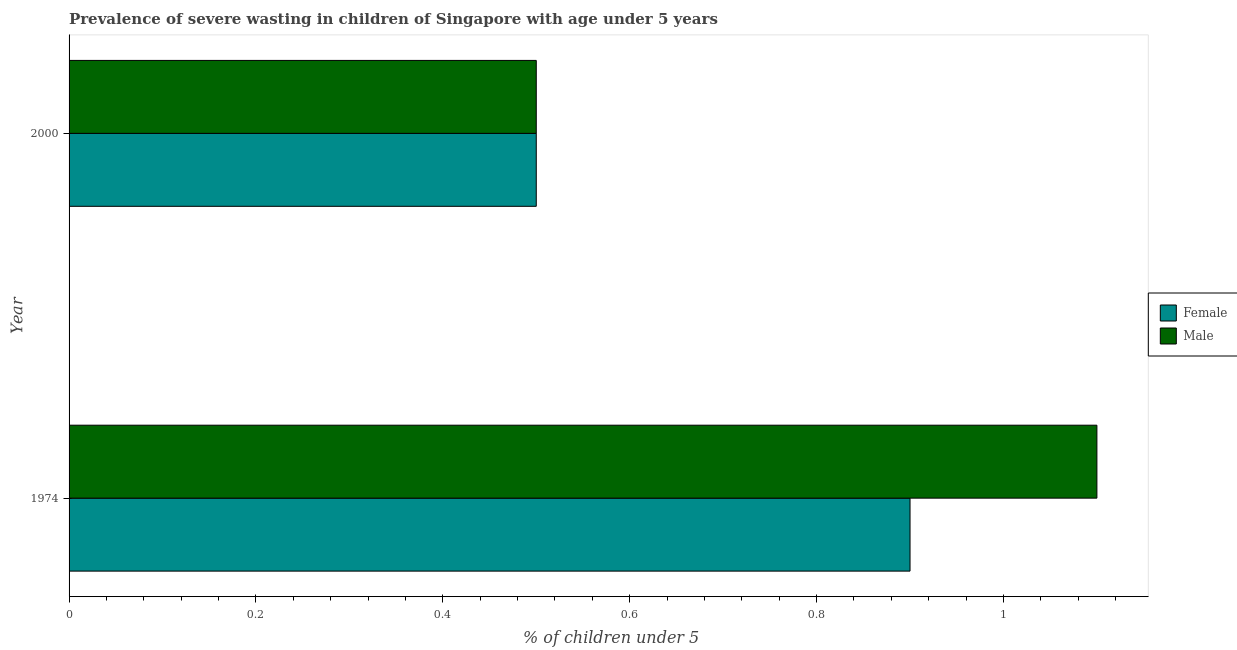

**Question**

How many bars are there on the 2nd tick from the top?

Query key          : pq_1
Gold (correct)     : 2.
Unevolved (seed)   : There are two bars on the 2nd tick from the top.   ← WRONG
Evolved            : 2.   ← CORRECT
Reloaded `evolved` for the benchmark cell below.


In [ ]:
import os
from pathlib import Path
import gc
import sys
import torch
from IPython.display import display, Markdown, Image as IPyImage
from evaluate_plotqa import find_contrastive_plotqa_sample

MAX_CONTRASTIVE_SCAN = int(os.environ.get("MAX_CONTRASTIVE_SCAN", "120"))


def _vram_detach(mod_name: str) -> None:
    if mod_name in sys.modules:
        m = sys.modules.pop(mod_name)
        for attr in ("_model", "_processor"):
            if hasattr(m, attr):
                setattr(m, attr, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


_vram_detach("evolved_plotqa_colab")
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"Scanning up to {MAX_CONTRASTIVE_SCAN} seed failures on PlotQA …")
seed_v = load_module("_contrast_seed", PROJECT_ROOT / "seed_instruct.py")
evo_v = load_module("_contrast_evo", PROJECT_ROOT / "evolved_plotqa.py")
pair = find_contrastive_plotqa_sample(seed_v, evo_v, max_failure_checks=MAX_CONTRASTIVE_SCAN)
_vram_detach("_contrast_seed")
_vram_detach("_contrast_evo")

if pair is None:
    display(Markdown("### No contrastive example found"))
    print(
        f"No chart in the first {MAX_CONTRASTIVE_SCAN} seed failures where "
        "unevolved is wrong AND evolved is correct."
    )
    print("Try increasing MAX_CONTRASTIVE_SCAN or re-running evolution.")
else:
    CONTRASTIVE_SAMPLE = pair
    p = Path(pair["image_path"])
    if not p.is_file():
        raise FileNotFoundError(p)
    display(Markdown("## Contrastive chart from PlotQA"))
    display(Markdown("*Unevolved (seed) is wrong; evolved matches gold.*"))
    display(IPyImage(filename=str(p)))
    q = pair["question"]
    display(Markdown("**Question**"))
    display(Markdown((q[:2000] + "…") if len(q) > 2000 else q))
    print("Query key          :", pair["key"])
    print("Gold (correct)     :", pair["gold"])
    print("Unevolved (seed)   :", pair["seed_response"], "  ← WRONG")
    print("Evolved            :", pair["evolved_response"], "  ← CORRECT")

evolved = load_module("evolved_plotqa_colab", PROJECT_ROOT / "evolved_plotqa.py")
print("Reloaded `evolved` for the benchmark cell below.")



In [ ]:
from evaluate_plotqa import evaluate

print("=== BENCHMARK — after AlphaEvolve ===")
bench_after = evaluate(evolved, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_after[k]}")
print("\n=== SUMMARY (PlotQA / SmolVLM2-2.2B-Instruct: seed → evolved) ===")
print(f"Accuracy: {bench_before['desc_accuracy']:.4f} → {bench_after['desc_accuracy']:.4f}")
print("\n=== SAME-SAMPLE BEFORE / AFTER ===")
try:
    q = SAMPLE["question"]
    print("Question (trim):", (q[:240] + "…") if len(q) > 240 else q)
    print("Gold     :", SAMPLE["gold"])
    print("Seed pred:", before_pred)
    print("Evolved  :", after_pred)
except NameError:
    print("(Re-run the two EXAMPLE cells so `before_pred` and `after_pred` exist.)")


=== BENCHMARK — after AlphaEvolve ===


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  desc_accuracy: 0.21354166666666666
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 106.81370759010315
  avg_time_per_query: 0.5563213936984539

=== SUMMARY (PlotQA / SmolVLM2-2.2B-Instruct: seed → evolved) ===
Accuracy: 0.1250 → 0.2135

=== SAME-SAMPLE BEFORE / AFTER ===
Question (trim): Are the number of bars on each tick of the Y-axis equal?
Gold     : Yes.
Seed pred:  Yes.
Evolved  :  Yes.
